In [65]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.signal as signal

In [119]:
freqs = np.array([0.1, 0.25, 0.4])
w = np.array([1, 0.7, 0.3])
fs = 4
fN = fs / 2
T = 100
N = T * fs
delta_f = 1 / T
t = np.arange(N, dtype=float) / fs
y = np.sum([w * np.sin(2*np.pi * f * t) for w, f in zip(w, freqs)], axis=0)

print(f"{N=}, {delta_f=}, {fN=}")

N=400, delta_f=0.01, fN=2.0


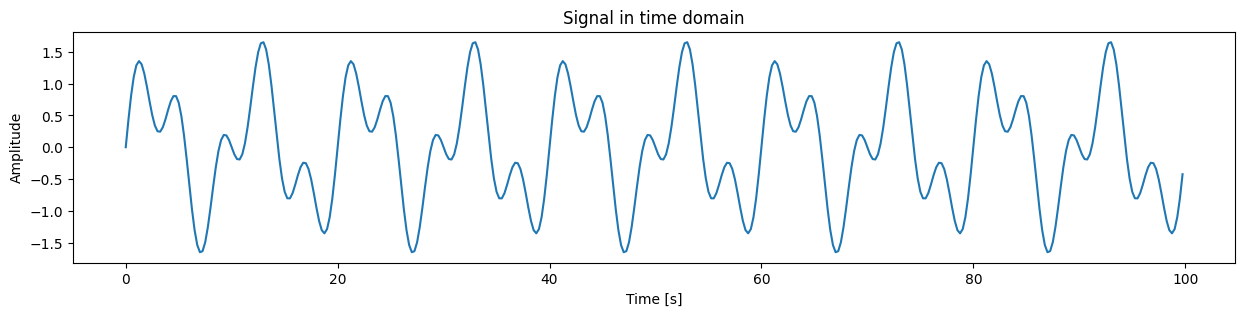

In [118]:
plt.figure(figsize=(15, 3))
plt.plot(t, y)
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Signal in time domain")
plt.show()

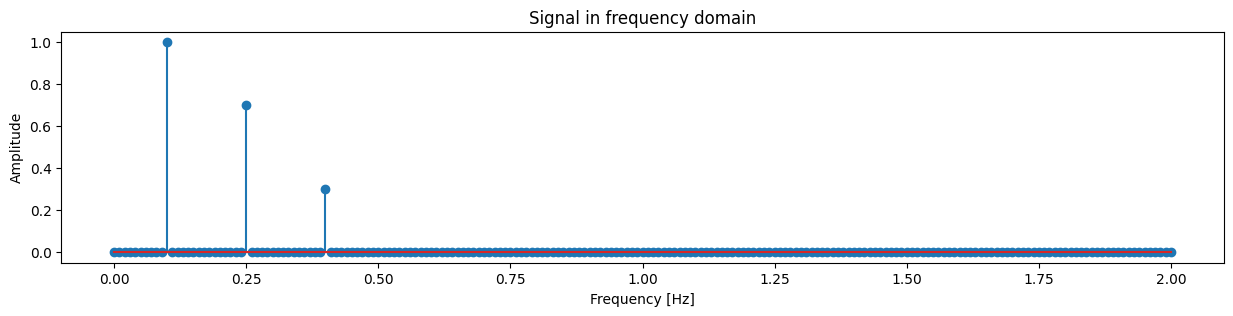

In [91]:
# f_vec = np.arange(N/2 + 1) * delta_f
f_vec = np.fft.rfftfreq(N, d=1 / fs)
dft_result = np.fft.rfft(y)

amplitude_spectrum = np.abs(dft_result) / N
amplitude_spectrum[1:-1] *= 2

plt.figure(figsize=(15, 3))
plt.stem(f_vec, amplitude_spectrum)
plt.xlabel("Frequency [Hz]")
plt.ylabel("Amplitude")
plt.title("Signal in frequency domain")
plt.show()

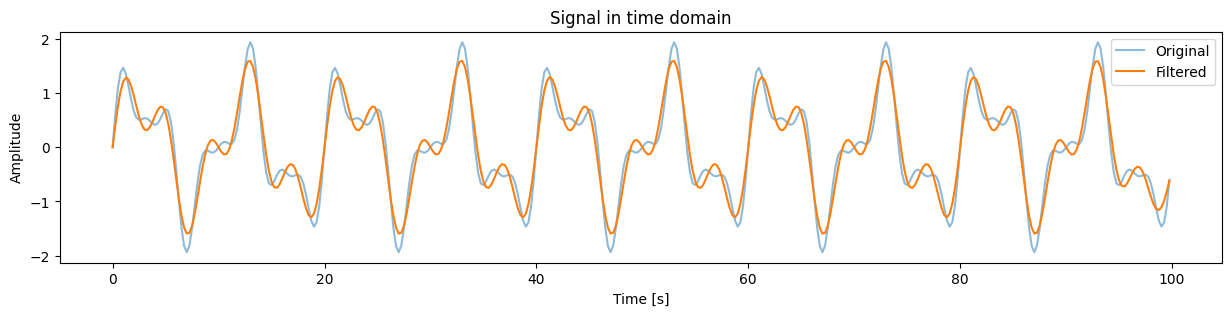

In [115]:
b, a = signal.butter(6, 0.3 / fN, "low")
filtered = signal.filtfilt(b, a, y)

plt.figure(figsize=(15, 3))
plt.plot(t, y, label="Original", alpha=0.5)
plt.plot(t, filtered, label="Filtered")
plt.legend()
plt.xlabel("Time [s]")
plt.ylabel("Amplitude")
plt.title("Signal in time domain")
plt.show()

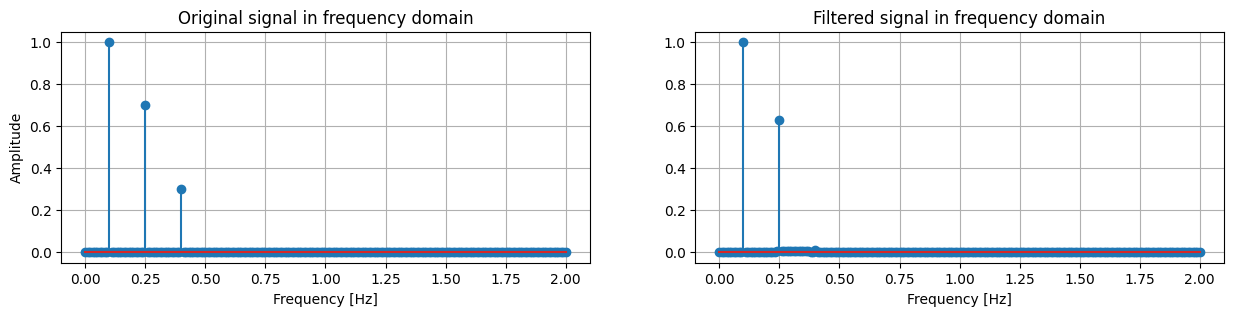

In [116]:
f_vec = np.fft.rfftfreq(N, d=1 / fs)
dft_result = np.fft.rfft(filtered)

filtered_amplitude_spectrum = np.abs(dft_result) / N
filtered_amplitude_spectrum[1:-1] *= 2

fig, axs = plt.subplots(1, 2, figsize=(15, 3))
axs[0].stem(f_vec, amplitude_spectrum)
axs[0].set_xlabel("Frequency [Hz]")
axs[0].set_ylabel("Amplitude")
axs[0].set_title("Original signal in frequency domain")
axs[0].grid(True)
axs[1].stem(f_vec, filtered_amplitude_spectrum)
axs[1].set_xlabel("Frequency [Hz]")
axs[1].set_title("Filtered signal in frequency domain")
axs[1].grid(True)
plt.show()